# Integrated Project 1. Video Game Market Analysis

**Goal:** Analyze data from open sources on game sales, user and expert ratings, genres and platforms, and identify the main factors of a game's commercial success.

**Plan:**
- 1. General information about the data
- 2. Data preparation
    - 2.1 Data transformation
    - 2.2 Calculation of additional parameters
- 3. Exploratory data analysis
    - 3.1 Choosing the current gaming platforms and the release period
    - 3.2 Sales by current platform
    - 3.3 Influence of user and critic reviews on sales
    - 3.4 Influence of the game genre on sales
- 4. User profile of each region
- 5. Hypothesis testing
    - 5.1 Removing outliers in user scores
    - 5.2 Average user ratings of the Xbox One and PC platforms
    - 5.3 Average user ratings of the Action and Sports genres
- 6. Overall conclusion

**Data description:**
The data is stored in the file `games.csv`.
- `Name` - game title
- `Platform` - platform
- `Year_of_Release` - release year
- `Genre` - game genre
- `NA_sales` - sales in North America (millions of copies sold)
- `EU_sales` - sales in Europe (millions of copies sold)
- `JP_sales` - sales in Japan (millions of copies sold)
- `Other_sales` - sales in other countries (millions of copies sold)
- `Critic_Score` - critic score (maximum 100)
- `User_Score` - user score (maximum 10)
- `Rating` - rating from the ESRB (Entertainment Software Rating Board), the organization that assigns age ratings to video games.

## Step 1. General Information About the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display
import math
from scipy import stats as st

Load the data from `games.csv`, print the first 10 rows for a first look at the data and study the table structure with `info()`: data types, number of rows and columns, missing values.

In [2]:
# read the data from the .csv file with read_csv()
games = pd.read_csv('games.csv')
# print the first 10 rows of the table with head()
display(games.head(10))
# study the table structure with info(): data types, numbers of rows and columns, missing values.
games.info()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [3]:
print('Number of duplicated rows:', sum(games.duplicated()))

Number of duplicated rows: 0


### Conclusions

- The data is loaded successfully. The table `games` has 16715 records. No duplicates are found. The data matches the description.
- The general information about the table is studied.
    - The data type of `Year_of_Release` must be changed to `int64`.
    - The data type of `User_Score` must be changed to `float`.
- Some columns have up to 50% missing values. The missing values are studied and handled below.
- Further study of the data is needed to find hidden errors and outliers.

## Step 2. Data Preparation

### 2.1 Data Transformation

**1) Renaming the columns**

Convert the column names to lower case.

In [4]:
# lower-case the column names with str.lower()
games.columns = games.columns.str.lower()
display(games.head())

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


**2) Game titles in the column `name`**

The data type of `name` matches the stored information (`object` for game titles).
Look for the missing values.

In [5]:
# use isna()
games.loc[games['name'].isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993.0,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993.0,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


Only 2 records have a missing title. Without the title these records are of no use, and most of their other fields are also empty. Removing them does not distort the distributions of the other parameters.

In [6]:
games = games.loc[~games['name'].isna()]

In [7]:
print('Number of games considered in the project:', len(games['name'].unique()))

Number of games considered in the project: 11559


**3) Gaming platforms in the column `platform`**

The data type of `platform` matches the stored information (`object` for the platform name). There are no missing values.
Look at the distribution of the column with a histogram.

In [8]:
def show_counts(column, title):
    """
    input: column - data column to plot the histogram for
    output: None
    description: The function plots a histogram of the selected column with seaborn's countplot().
                 the data is sorted by descending frequency
    """
    plt.figure(figsize=(14,4))
    sns.set()
    sns.countplot(x=column, 
                  data=games,
                  order = games[column].value_counts().index)
    plt.title(title + '. Frequency histogram', fontsize=18)
    plt.show()

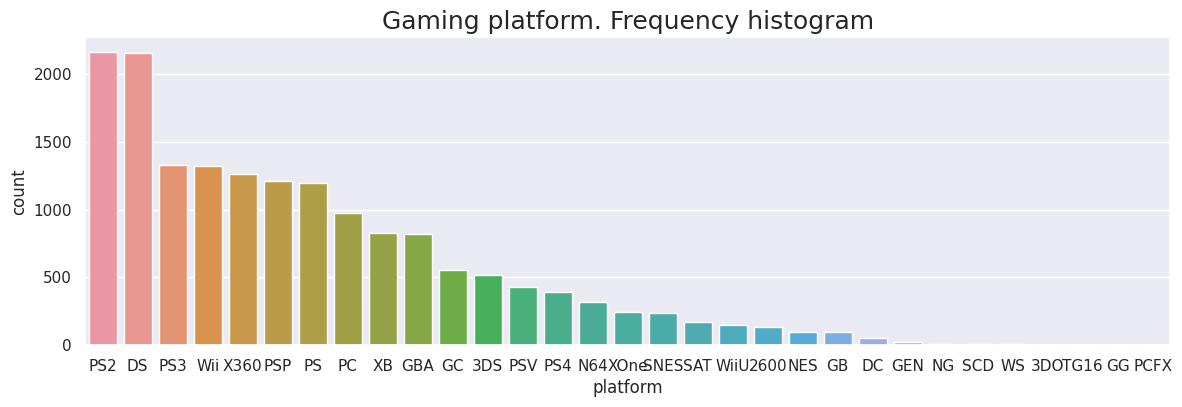

In [9]:
show_counts('platform', 'Gaming platform')

Most games are released on Sony, Nintendo and Microsoft platforms, and on PC. This matches the real situation on the video game market, so the sample looks representative.

**4) Release year in the column `year_of_release`**

`year_of_release` has 269 missing records (1.6%). Look at the rows with missing values.

In [10]:
games.loc[games['year_of_release'].isna()].tail(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
16277,Homeworld Remastered Collection,PC,NaN,Strategy,0.00,0.01,0.00,0.0,86.0,8.2,E10+
16288,Shorts,DS,NaN,Platform,0.01,0.00,0.00,0.0,NaN,tbd,E10+
16293,AKB1/48: Idol to Guam de Koishitara...,X360,NaN,Misc,0.00,0.00,0.01,0.0,NaN,NaN,NaN
16329,Brothers in Arms: Furious 4,X360,NaN,Shooter,0.01,0.00,0.00,0.0,NaN,NaN,M
16348,Agarest Senki: Re-appearance,PS3,NaN,Role-Playing,0.00,0.00,0.01,0.0,NaN,NaN,NaN
16373,PDC World Championship Darts 2008,PSP,NaN,Sports,0.01,0.00,0.00,0.0,43.0,tbd,E10+
16405,Freaky Flyers,GC,NaN,Racing,0.01,0.00,0.00,0.0,69.0,6.5,T
16448,Inversion,PC,NaN,Shooter,0.01,0.00,0.00,0.0,59.0,6.7,M
16458,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,0.01,0.00,0.00,0.0,NaN,NaN,NaN
16522,Virtua Quest,GC,NaN,Role-Playing,0.01,0.00,0.00,0.0,55.0,5.5,T


The values are missing for different games, platforms and genres. They were possibly lost during the export from the database or at the data collection stage (incorrect export from websites).
Many games are released on several platforms, so the release year can be copied from the records of the same game on other platforms. This is safe because most games are released on all platforms at the same time. The exceptions are a few exclusive Sony and Nintendo games, and the difference in release dates does not exceed a year. Possible rare errors in the release year will not noticeably change the distributions.

In [11]:
# Use fillna().
# Group the data by name with groupby() and fill the gaps with the first known year of the same game.
games = games.fillna({'year_of_release': games.groupby('name')['year_of_release'].transform('first')})

In [12]:
print('Number of games with unknown release year:', len(games.loc[games['year_of_release'].isna()]))
print('Share of games with unknown release year:', round(len(games.loc[games['year_of_release'].isna()])/len(games)*100, 2), '%')

Number of games with unknown release year: 146
Share of games with unknown release year: 0.87 %


The remaining games with an unknown release year are few (less than 1% of the data) and will not noticeably change the distributions.
Replace the missing values with **-1** and convert the column to the integer type `int16` to save memory.

In [13]:
games['year_of_release'] = games['year_of_release'].fillna(-1)
# use to_numeric() to convert the data type.
# downcast='integer' - convert to the smallest type sufficient to store the release year (int16)
games['year_of_release'] = pd.to_numeric(games['year_of_release'], downcast='integer') 

Look at the distribution of the column with a histogram.

In [14]:
def show_hists(data, data_label, num_bins, rug=False, log_scale=False):
    """
    input: data - data to plot the histogram for
           data_label - description of the data
           num_bins - number of bins
    output: None
    description: The function plots two histograms for the selected parameter:
                - Density (seaborn's distplot())
                - Frequency distribution (distplot(), kde=False)
    """
    sns.set()
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label + ". Density", fontsize=18)
    axes[0].set_ylabel('density', fontsize=15)
    sns.distplot(data, bins=num_bins, rug=rug, ax=axes[0])
    axes[1].set_title(data_label + ". Frequency distribution", fontsize=18)
    axes[1].set_ylabel('count', fontsize=15)
    sns.distplot(data, bins=num_bins, kde=False, ax=axes[1])
    plt.show()

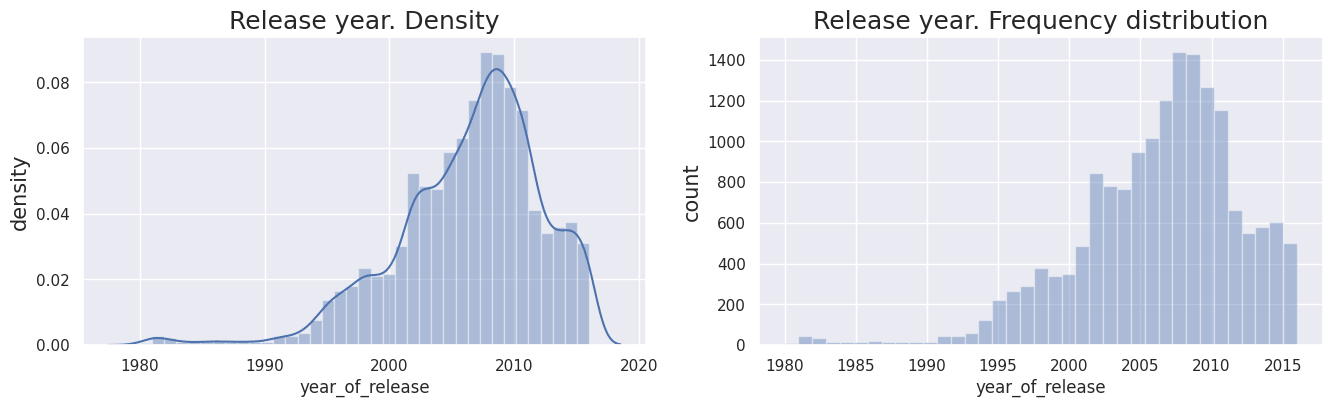

In [15]:
show_hists(games.loc[games['year_of_release'] > 0, 'year_of_release'], 'Release year', num_bins=37)

- Few games were released before 1990, so they can be neglected later.
- Most records fall in 2005-2010, followed by a sharp decline. This may be caused by a decrease in the number of gaming platforms or by the migration of the game industry to mobile platforms. This needs further study.

**5) Game genre in the column `genre`**

The data type of `genre` matches the stored information (`object` for the genre name). There are no missing values.
Look at the distribution of the column with a histogram.

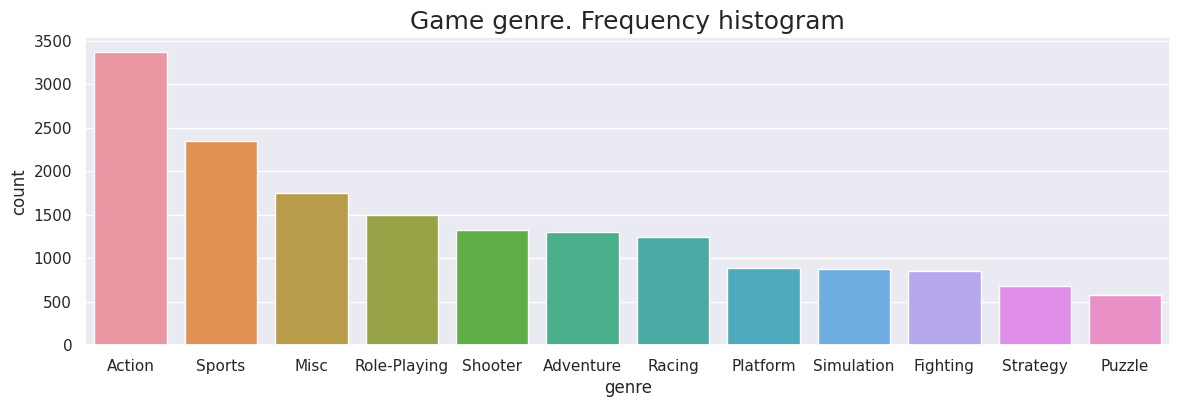

In [16]:
show_counts('genre', 'Game genre')

Action and sports games are produced most often. Strategy and puzzle games are the least popular. The data matches the real market situation, and there are no implausible jumps on the histogram, so the column is left unchanged.

**6) Sales in North America in the column `na_sales`**

- The data type of `na_sales` matches the stored information (`float64` for millions of copies sold).
There are no missing values.
- Look at the distribution of the column with a histogram and at its numerical summary from `describe()`.
- Zero values most likely mean that the game was not sold in the region. They are excluded from the plot so that they do not distort it.

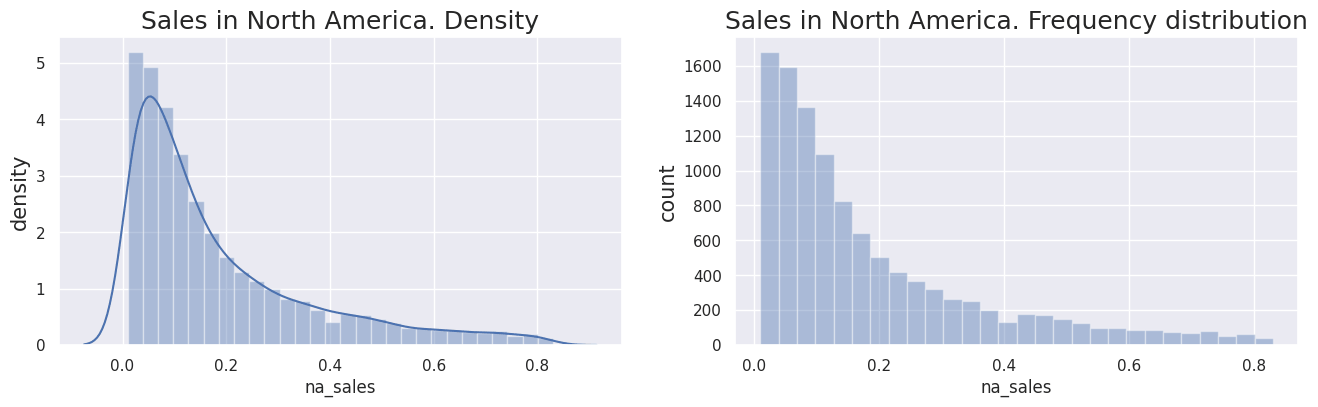

In [17]:
show_hists(games.loc[(games['na_sales'] > 0) & (games['na_sales'] < 0.84), 'na_sales'], 
           'Sales in North America',
           num_bins=28)

In [18]:
games.loc[games['na_sales'] > 0, 'na_sales'].describe()

count    12206.000000
mean         0.360525
std          0.933409
min          0.010000
25%          0.060000
50%          0.140000
75%          0.340000
max         41.360000
Name: na_sales, dtype: float64

The mean 0.36 is much larger than the median 0.14, so the data is strongly right-skewed. All values above 0.76 can be considered outliers ( (q.75 - q.25) * 1.5 + q.75 = 0.76 ).
Most games sell up to 0.76 million copies in North America, but a number of very popular games sell up to 41 million copies. These games skew the data.
Find the share of outliers in the data.

In [19]:
print('Share of outliers in the data:',
      round(len(games.loc[games['na_sales'] > 0.76]) / sum(games['na_sales'] > 0) * 100, 2), '%')

Share of outliers in the data: 10.54 %


Outliers make up **10.5%** of the games sold in the region. This is too many to simply drop, so the data is left as is for now.
Later in the study old games and unpopular consoles are excluded, which may remove part of the outliers.

**7) Sales in Europe in the column `eu_sales`**

- The data type of `eu_sales` matches the stored information (`float64` for millions of copies sold).
There are no missing values.
- Look at the distribution of the column with a histogram and at its numerical summary from `describe()`.
- Zero values most likely mean that the game was not sold in the region. They are excluded from the plot so that they do not distort it.

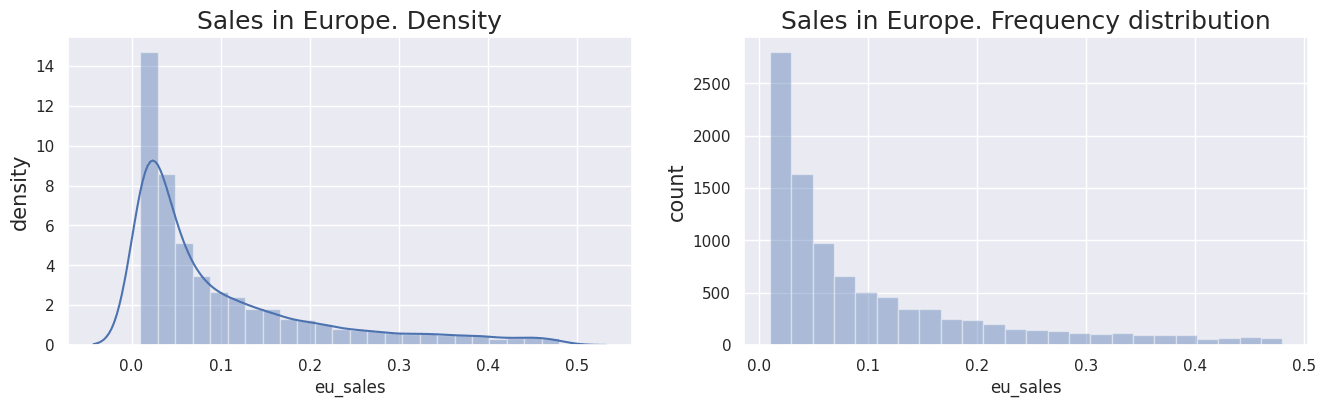

In [20]:
show_hists(games.loc[(games['eu_sales'] > 0) & (games['eu_sales'] < 0.49), 'eu_sales'], 
           'Sales in Europe',
           num_bins=24)

In [21]:
games.loc[games['eu_sales'] > 0, 'eu_sales'].describe()

count    10844.000000
mean         0.223547
std          0.610706
min          0.010000
25%          0.020000
50%          0.070000
75%          0.200000
max         28.960000
Name: eu_sales, dtype: float64

The mean 0.22 is much larger than the median 0.07, so the data is strongly right-skewed. All values above 0.47 can be considered outliers ( (q.75 - q.25) * 1.5 + q.75 = 0.47 ).
Most games sell up to 0.47 million copies in Europe, but a number of very popular games sell up to 29 million copies. These games skew the data.
Find the share of outliers in the data.

In [22]:
print('Share of outliers in the data:',
      round(len(games.loc[games['eu_sales'] > 0.47]) / sum(games['eu_sales'] > 0) * 100, 2), '%')

Share of outliers in the data: 10.69 %


Outliers make up **10.7%** of the games sold in the region. This is too many to simply drop, so the data is left as is for now.

**8) Sales in Japan in the column `jp_sales`**

- The data type of `jp_sales` matches the stored information (`float64` for millions of copies sold).
There are no missing values.
- Look at the distribution of the column with a histogram and at its numerical summary from `describe()`.
- Zero values most likely mean that the game was not sold in the region. They are excluded from the plot so that they do not distort it.

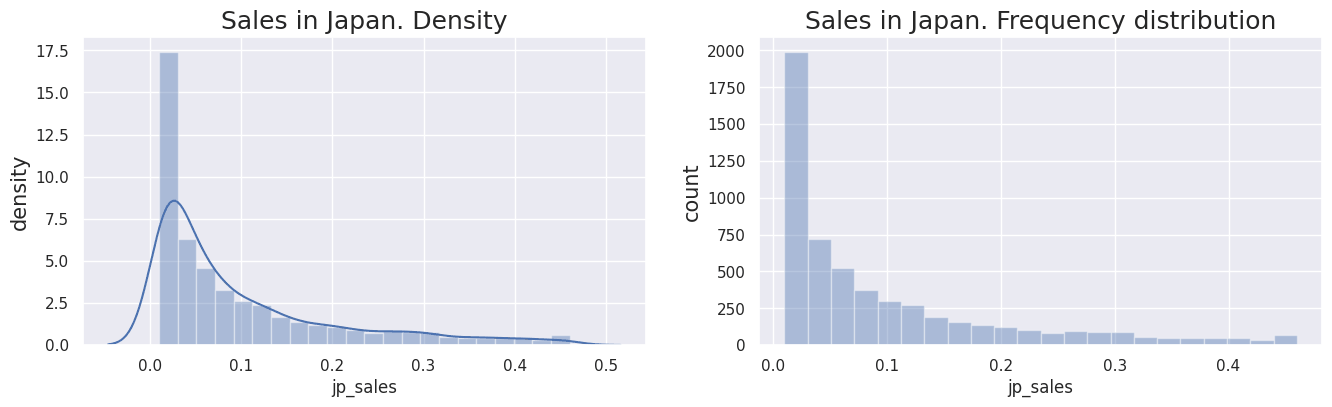

In [23]:
show_hists(games.loc[(games['jp_sales'] > 0) & (games['jp_sales'] < 0.47), 'jp_sales'], 
           'Sales in Japan',
           num_bins=22)

In [24]:
games.loc[games['jp_sales'] > 0, 'jp_sales'].describe()

count    6200.000000
mean        0.209248
std         0.479216
min         0.010000
25%         0.030000
50%         0.070000
75%         0.190000
max        10.220000
Name: jp_sales, dtype: float64

The mean 0.21 is much larger than the median 0.07, so the data is strongly right-skewed. All values above 0.43 can be considered outliers ( (q.75 - q.25) * 1.5 + q.75 = 0.43 ).
Most games sell up to 0.43 million copies in Japan, but a number of very popular games sell up to 10 million copies. These games skew the data.
Find the share of outliers in the data.

In [25]:
print('Share of outliers in the data:',
      round(len(games.loc[games['jp_sales'] > 0.43]) / sum(games['jp_sales'] > 0) * 100, 2), '%')

Share of outliers in the data: 10.9 %


Outliers make up **10.9%** of the games sold in the region. This is too many to simply drop, so the data is left as is for now.

**9) Sales in other countries in the column `other_sales`**

- The data type of `other_sales` matches the stored information (`float64` for millions of copies sold).
There are no missing values.
- Look at the distribution of the column with a histogram and at its numerical summary from `describe()`.
- Zero values most likely mean that the game was not sold in the region. They are excluded from the plot so that they do not distort it.

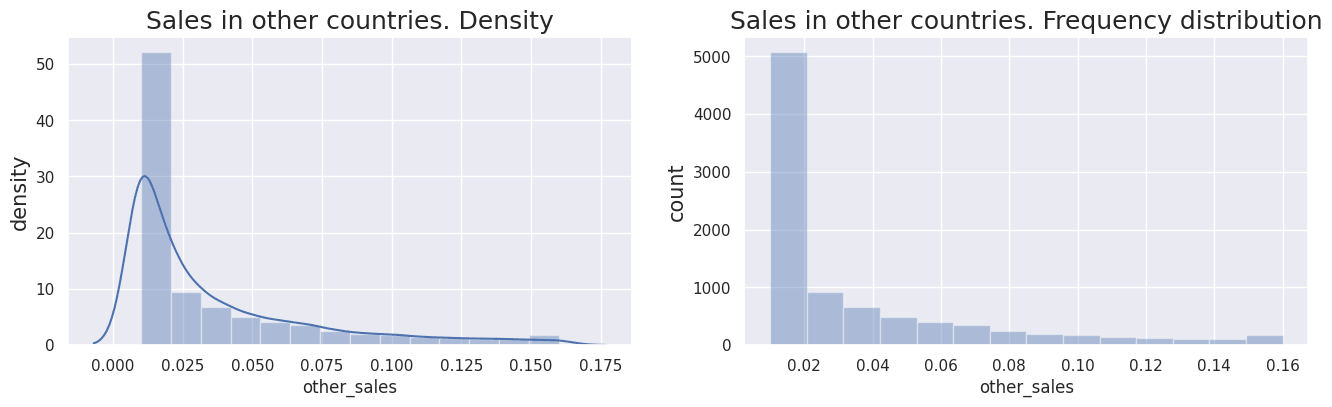

In [26]:
show_hists(games.loc[(games['other_sales'] > 0) & (games['other_sales'] < 0.17), 'other_sales'], 
           'Sales in other countries',
           num_bins=14)

In [27]:
games.loc[games['other_sales'] > 0, 'other_sales'].describe()

count    10113.00000
mean         0.07824
std          0.23498
min          0.01000
25%          0.01000
50%          0.02000
75%          0.07000
max         10.57000
Name: other_sales, dtype: float64

The mean 0.08 is much larger than the median 0.02, so the data is strongly right-skewed. All values above 0.16 can be considered outliers ( (q.75 - q.25) * 1.5 + q.75 = 0.16 ).
Most games sell up to 0.16 million copies in the other countries, but a number of very popular games sell up to 10.6 million copies. These games skew the data.
Find the share of outliers in the data.

In [28]:
print('Share of outliers in the data:',
      round(len(games.loc[games['other_sales'] > 0.16]) / sum(games['other_sales'] > 0) * 100, 2), '%')

Share of outliers in the data: 10.18 %


Outliers make up **10.2%** of the games sold in the region. This is too many to simply drop, so the data is left as is for now.

**10) Critic scores in the column `critic_score`**

- The data type of `critic_score` matches the stored information (`float64` for critic scores).
- The column has many missing values (about 50%). Look at the rows with missing values.

In [29]:
games.loc[games['critic_score'].isna()].head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN
12,Pokemon Gold/Pokemon Silver,GB,1999,Role-Playing,9.00,6.18,7.20,0.71,NaN,NaN,NaN
18,Super Mario World,SNES,1990,Platform,12.78,3.75,3.54,0.55,NaN,NaN,NaN
20,Pokemon Diamond/Pokemon Pearl,DS,2006,Role-Playing,6.38,4.46,6.04,1.36,NaN,NaN,NaN
21,Super Mario Land,GB,1989,Platform,10.83,2.71,4.18,0.42,NaN,NaN,NaN
22,Super Mario Bros. 3,NES,1988,Platform,9.54,3.44,3.84,0.46,NaN,NaN,NaN


- The values are missing for different platforms, release years and genres. The scores were possibly not available when the data was collected, or they were lost during the export from the database.
- The scores cannot be imputed from the existing data, because games of the same genre, release year, etc. can differ greatly from each other. Scores of the same game on different platforms can also differ greatly.
- The missing values are left as is for now. Records of old games and non-current platforms are removed later, which may remove part of the missing values.

- Look at the distribution of the column with a histogram and build a `violin` plot to find the outliers.

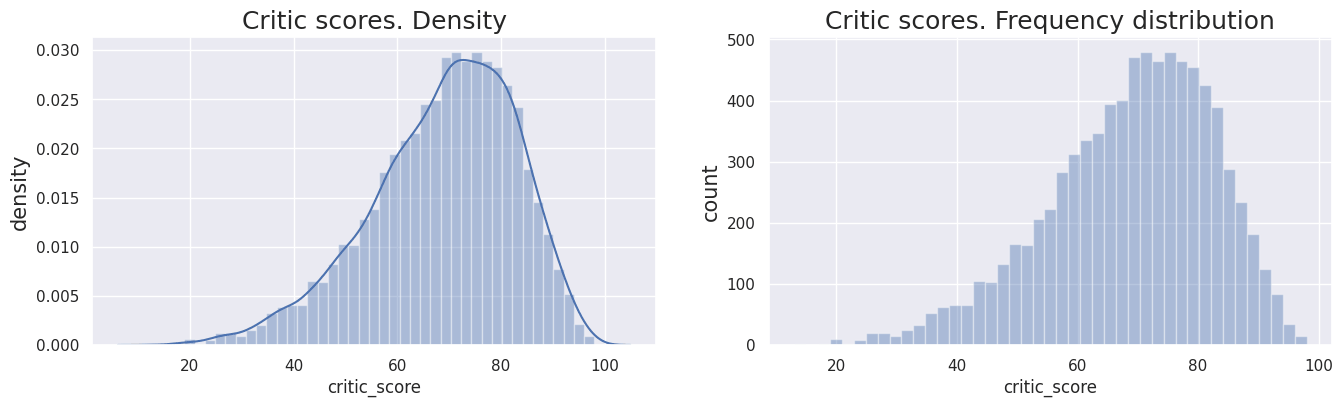

In [30]:
show_hists(games['critic_score'], 'Critic scores', num_bins=43)

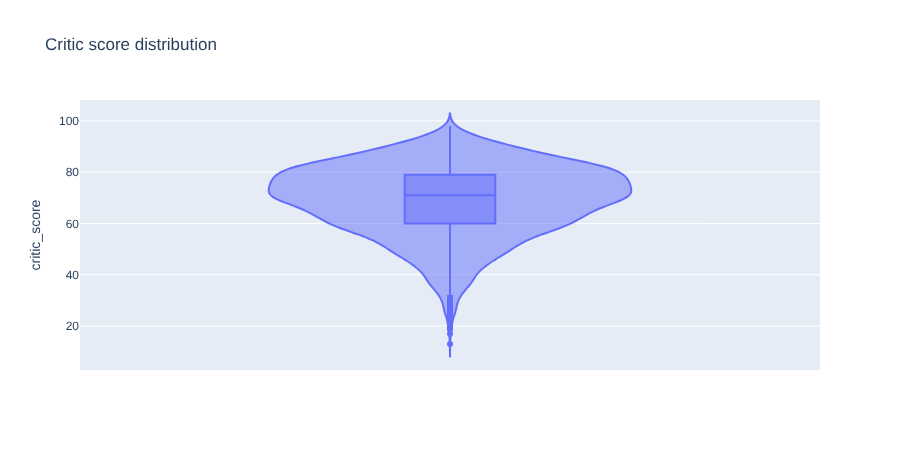

In [31]:
# plot the distribution of critic scores with violin() from plotly.
# box=True - to show a box plot inside the violin
px.violin(games, y="critic_score", 
          box=True, title = 'Critic score distribution')

In [32]:
print('Mean critic score:', round(games['critic_score'].mean(), 2))

Mean critic score: 68.97


The mean 69 is slightly lower than the median 71, so the data is slightly left-skewed. All values below 31 can be considered outliers.
Find the share of outliers among the scores.

In [33]:
print('Share of outliers in the data:',
      round(len(games.loc[games['critic_score'] <= 31]) / games['critic_score'].count() * 100, 2), '%')

Share of outliers in the data: 1.02 %


The share of outliers is small (1% of all critic scores), so they could be removed without a large effect on the distribution.
The data is left as is for now (until the current platforms and the current release period are chosen).

**11) User scores in the column `user_score`**

- The data type of `user_score` does not match the stored information, so it is changed to `float64` for user scores.
- First, deal with the value `tbd`. It stands for "to be determined" and means that the game had no score at the time of data collection. Replace `tbd` with `NaN`.

In [34]:
games.loc[games['user_score'] == "tbd", 'user_score'] = np.nan

In [35]:
# use to_numeric() to convert the data type
# downcast='float' - convert to the smallest type sufficient to store the scores (float32)
games['user_score'] = pd.to_numeric(games['user_score'], downcast='float') 

- The column has many missing values (about 55%). Look at the rows with missing values.

In [36]:
games.loc[games['user_score'].isna()].head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN
12,Pokemon Gold/Pokemon Silver,GB,1999,Role-Playing,9.00,6.18,7.20,0.71,NaN,NaN,NaN
18,Super Mario World,SNES,1990,Platform,12.78,3.75,3.54,0.55,NaN,NaN,NaN
20,Pokemon Diamond/Pokemon Pearl,DS,2006,Role-Playing,6.38,4.46,6.04,1.36,NaN,NaN,NaN
21,Super Mario Land,GB,1989,Platform,10.83,2.71,4.18,0.42,NaN,NaN,NaN
22,Super Mario Bros. 3,NES,1988,Platform,9.54,3.44,3.84,0.46,NaN,NaN,NaN


- The values are missing for different platforms, release years and genres. The scores were possibly not available when the data was collected, or they were lost during the export from the database.
- The scores cannot be imputed from the existing data, because games of the same genre, release year, etc. can differ greatly from each other. Scores of the same game on different platforms can also differ greatly.
- The missing values are left as is for now. Records of old games and non-current platforms are removed later, which may remove part of the missing values.

- Look at the distribution of the column with a histogram and build a `violin` plot to find the outliers.

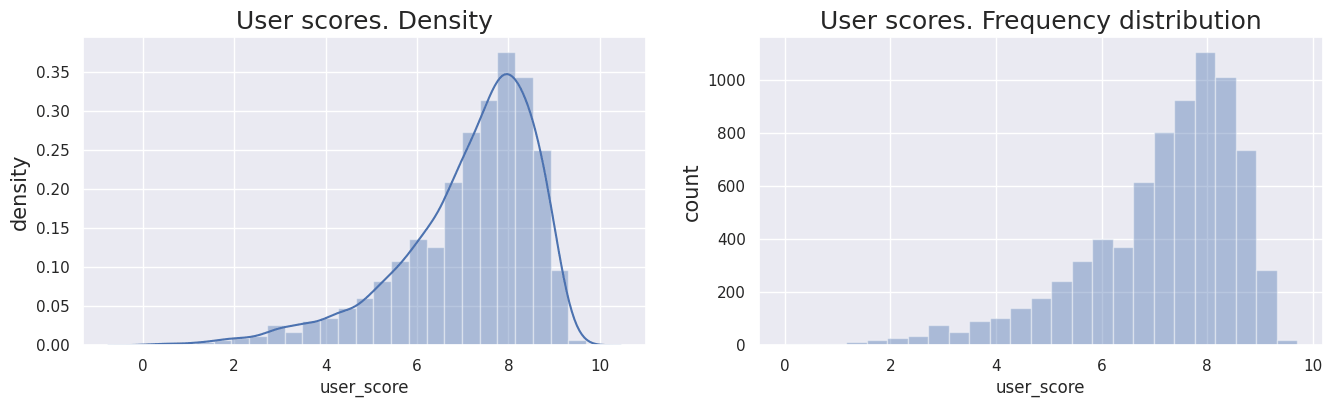

In [37]:
show_hists(games['user_score'], 'User scores', num_bins=25)

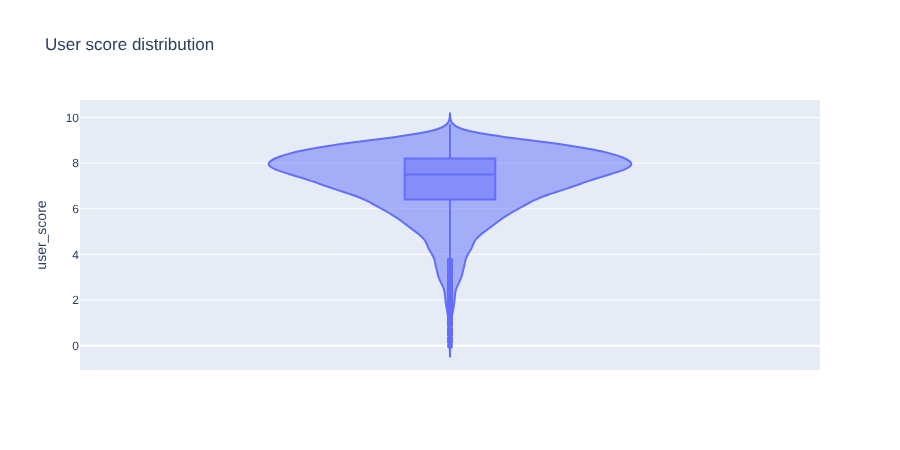

In [38]:
# plot the distribution of user scores with violin() from plotly.
# box=True - to show a box plot inside the violin
px.violin(games, y="user_score", 
          box=True, title = 'User score distribution')

In [39]:
print('Mean user score:', round(games['user_score'].mean(), 2))

Mean user score: 7.13


The mean 7.13 is slightly lower than the median 7.5, so the data is slightly left-skewed. All values below 3.7 can be considered outliers.
Find the share of outliers among the scores.

In [40]:
print('Share of outliers in the data:',
      round(len(games.loc[games['user_score'] <= 3.7]) / games['user_score'].count() * 100, 2), '%')

Share of outliers in the data: 4.02 %


The share of outliers is high (4% of all user scores), so removing them may affect the distribution.
The data is left as is for now (until the current platforms and the current release period are chosen).

**12) ESRB rating in the column `rating`**

- The data type of `rating` matches the stored information (`object` for rating abbreviations).
- Look at the possible ratings.

In [41]:
games['rating'].unique()

array(['E', nan, 'M', 'T', 'E10+', 'K-A', 'AO', 'EC', 'RP'], dtype=object)

According to the ESRB website (https://www.esrb.org/ratings-guide/):
- `E` - everyone
- `M` - mature (17 and older)
- `T` - teen (13 and older)
- `E10+` - everyone 10+ (10 and older)
- `K-A` - kids to adults (the old name of the "E" rating)
- `AO` - adults only (18 and older)
- `EC` - early childhood (replaced by "E" because it was rarely used)
- `RP` - rating pending

Replace `EC` and `K-A` with `E`. There are only 3 `RP` values, so replace them with np.nan (undefined rating).

In [42]:
games.loc[(games['rating'] == 'EC') | (games['rating'] == 'K-A'), 'rating'] = 'E'
games.loc[games['rating'] == 'RP', 'rating'] = np.nan
games['rating'].unique()

array(['E', nan, 'M', 'T', 'E10+', 'AO'], dtype=object)

- The column has many missing values (about 40%). Look at the rows with missing values.

In [43]:
games.loc[games['rating'].isna()].head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN
12,Pokemon Gold/Pokemon Silver,GB,1999,Role-Playing,9.00,6.18,7.20,0.71,NaN,NaN,NaN
18,Super Mario World,SNES,1990,Platform,12.78,3.75,3.54,0.55,NaN,NaN,NaN
20,Pokemon Diamond/Pokemon Pearl,DS,2006,Role-Playing,6.38,4.46,6.04,1.36,NaN,NaN,NaN
21,Super Mario Land,GB,1989,Platform,10.83,2.71,4.18,0.42,NaN,NaN,NaN
22,Super Mario Bros. 3,NES,1988,Platform,9.54,3.44,3.84,0.46,NaN,NaN,NaN


- The values are missing for different platforms, release years and genres. The ratings were possibly not available when the data was collected, or they were lost during the export from the database.
- The ratings cannot be imputed from the existing data, because games of the same genre, release year, etc. can differ greatly from each other.
- The missing values are left as is for now. Records of old games and non-current platforms are removed later, which may remove part of the missing values.

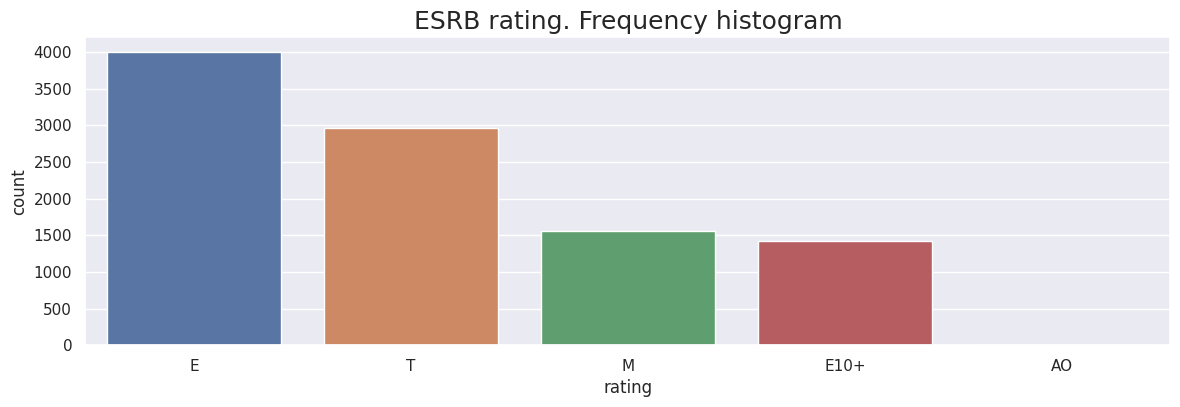

In [44]:
show_counts('rating', 'ESRB rating')

Most of the data is split between the ratings 'E', 'M', 'T' and 'E10+'. The rating 'AO' has only one record. Game publishers try to create content for as many users as possible, because this increases sales.

### 2.2 Calculation of Additional Parameters

- Calculate the total sales in all regions and save them in the column `tot_sales`.

In [45]:
games['tot_sales'] = games[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].sum(axis=1)

- The data type of `tot_sales` matches the stored information (`float64` for millions of copies sold).
There are no missing values.

In [46]:
# find the rows with zero sales in all regions
games.loc[games['tot_sales'] == 0]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,tot_sales
16676,G1 Jockey 4 2008,PS3,2008,Sports,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0
16709,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0


Two records have no sales and no score data. They can be removed without harming the further study.

In [47]:
games = games.loc[games['tot_sales'] > 0]

- Look at the distribution of the column with a histogram and at its numerical summary from `describe()`.
- There are almost no zero values in the column, because every game was sold in at least one region.

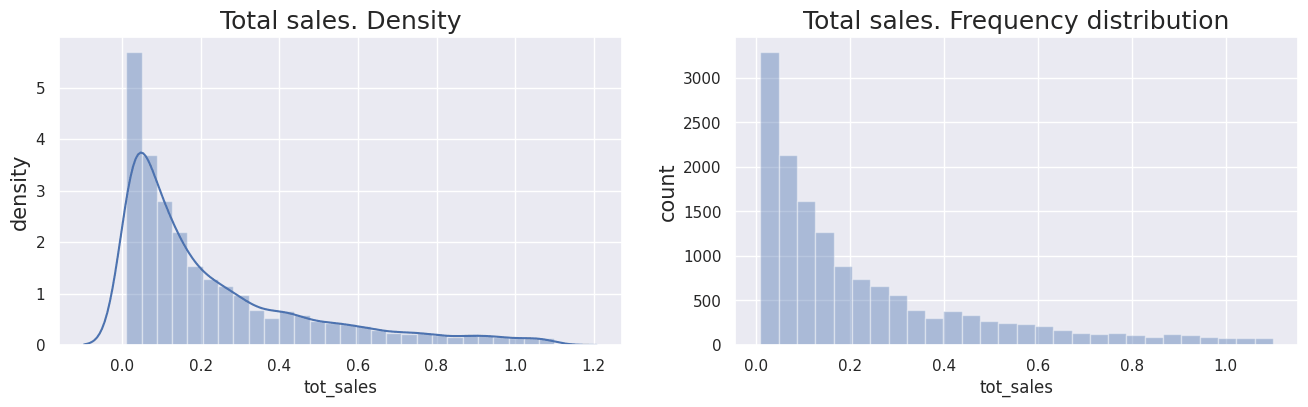

In [48]:
show_hists(games.loc[games['tot_sales'] < 1.1, 'tot_sales'], 
           'Total sales', 
           num_bins=28)

In [49]:
games['tot_sales'].describe()

count    16711.000000
mean         0.533379
std          1.548364
min          0.010000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.540000
Name: tot_sales, dtype: float64

The mean 0.53 is much larger than the median 0.17, so the data is strongly right-skewed. All values above 1.09 can be considered outliers.
Most games sell up to 1.09 million copies worldwide, but a number of very popular games sell up to 82.5 million copies. These games skew the data.
Find the share of outliers in the data.

In [50]:
print('Share of outliers in the data:',
      round(len(games.loc[games['tot_sales'] >= 1.09]) / len(games) * 100, 2), '%')

Share of outliers in the data: 11.27 %


Outliers make up **11.3%** of the games sold worldwide. This is too many to simply drop, so the data is left as is for now.

In [51]:
# look at the general table information after the transformations
games.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16711 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16711 non-null  object 
 1   platform         16711 non-null  object 
 2   year_of_release  16711 non-null  int16  
 3   genre            16711 non-null  object 
 4   na_sales         16711 non-null  float64
 5   eu_sales         16711 non-null  float64
 6   jp_sales         16711 non-null  float64
 7   other_sales      16711 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float32
 10  rating           9946 non-null   object 
 11  tot_sales        16711 non-null  float64
dtypes: float32(1), float64(6), int16(1), object(4)
memory usage: 1.5+ MB


### Conclusions

- The column names are converted to lower case.
- The data types are converted to match the stored information.
    - The release year `year_of_release` is converted to `int16` to save memory.
    - The user score `user_score` is converted to `float32` (the values `tbd` are replaced with `np.nan`, because there is no score in this case).
- The missing values are studied and handled.
    - In `year_of_release` the missing values are replaced, where possible, with the release year of the same game on another platform.
    The remaining missing values are replaced with -1 (so that the column can be converted to an integer type).
    - In `user_score` the values `tbd` are replaced with `np.nan`, because the score is absent in this case.
    - In `rating` the values `RP` are replaced with `np.nan`, because the rating is absent in this case.
    - In the other columns the missing values are left as is, because they cannot be handled with the available information. The share of missing values reaches 55%. Part of them may be removed when the current period and the current platforms are chosen below.
    - Possible reasons for the missing values: the information was absent when the data was collected, or a failure occurred during the export from the database.
- The parameter of total sales is added in the column `tot_sales`.
- The distributions of the numerical parameters are studied.
    - The sales data is strongly right-skewed. The share of outliers reaches 11.3%.
    Most games sell up to 1.09 million copies worldwide, but a number of very popular games sell up to 82.5 million copies. These games skew the data.
    - The score data is slightly left-skewed. The share of outliers reaches 4%.
    - The outliers are not removed yet and will be handled after the current period and the current platforms are chosen.
- In `rating` the old values are replaced with the current ones (according to the ESRB website).

## Step 3. Exploratory Data Analysis

### 3.1 Choosing the Current Gaming Platforms and the Release Period

Look at the distribution of the game release year with a histogram.

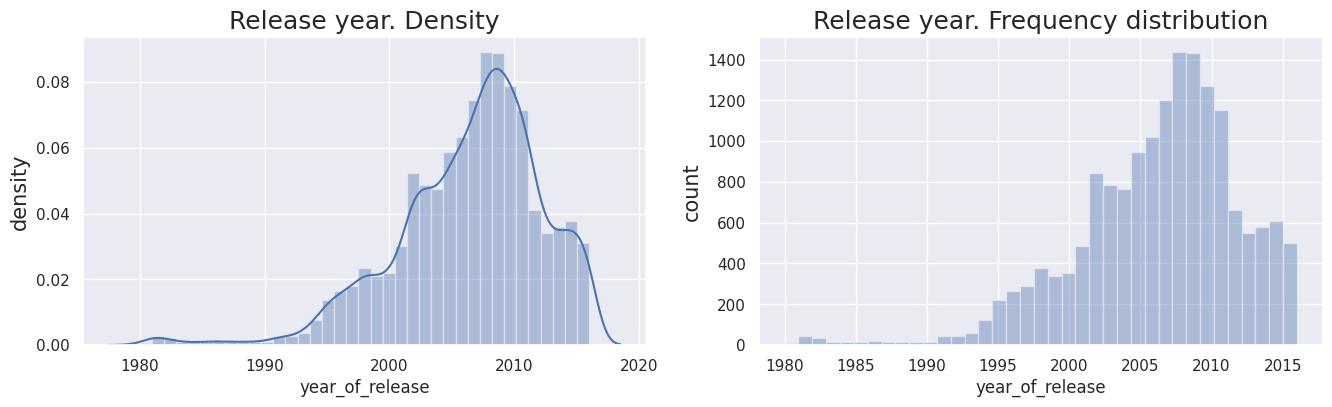

In [52]:
show_hists(games.loc[games['year_of_release'] > 0, 'year_of_release'], 'Release year', num_bins=37)

- Few games were released before 1990, and such games are outdated, so there is no need to take them into account.
- Besides the release year, the relevance of the platforms must be considered. Look at how the sales changed by platform:
    - Find the platforms with games released in 2016
    - Choose the ones with the highest total sales
    - Plot the total sales by year.

In [53]:
# find the platforms that had games released in 2016
cur_platforms = (games
                 .loc[games['year_of_release'] == 2016, 'platform']
                 .unique()
                )
print('Current platforms in 2016:', cur_platforms)

Current platforms in 2016: ['PS4' '3DS' 'XOne' 'WiiU' 'PS3' 'PC' 'X360' 'PSV' 'Wii']


In [54]:
# find the platforms with the highest sales of all time
top_platforms = (games
                 .groupby('platform')['tot_sales']      # group by platform and select total sales
                 .agg('sum')                            # total sales over all years
                 .sort_values(ascending=False)          # sort in descending order
                 .reset_index()                         # move the index (platform) into a separate column for convenience
                 .head(20)                              # drop platforms with small sales
                 ['platform']
                )
print('Platforms with the highest total sales:',
     top_platforms.values.reshape(1,len(top_platforms)))

Platforms with the highest total sales: [['PS2' 'X360' 'PS3' 'Wii' 'DS' 'PS' 'GBA' 'PS4' 'PSP' 'PC' '3DS' 'XB'
  'GB' 'NES' 'N64' 'SNES' 'GC' 'XOne' '2600' 'WiiU']]


- Determine the typical lifetime of a gaming platform. For this, plot a `lineplot` of total sales by year for the main gaming platforms.

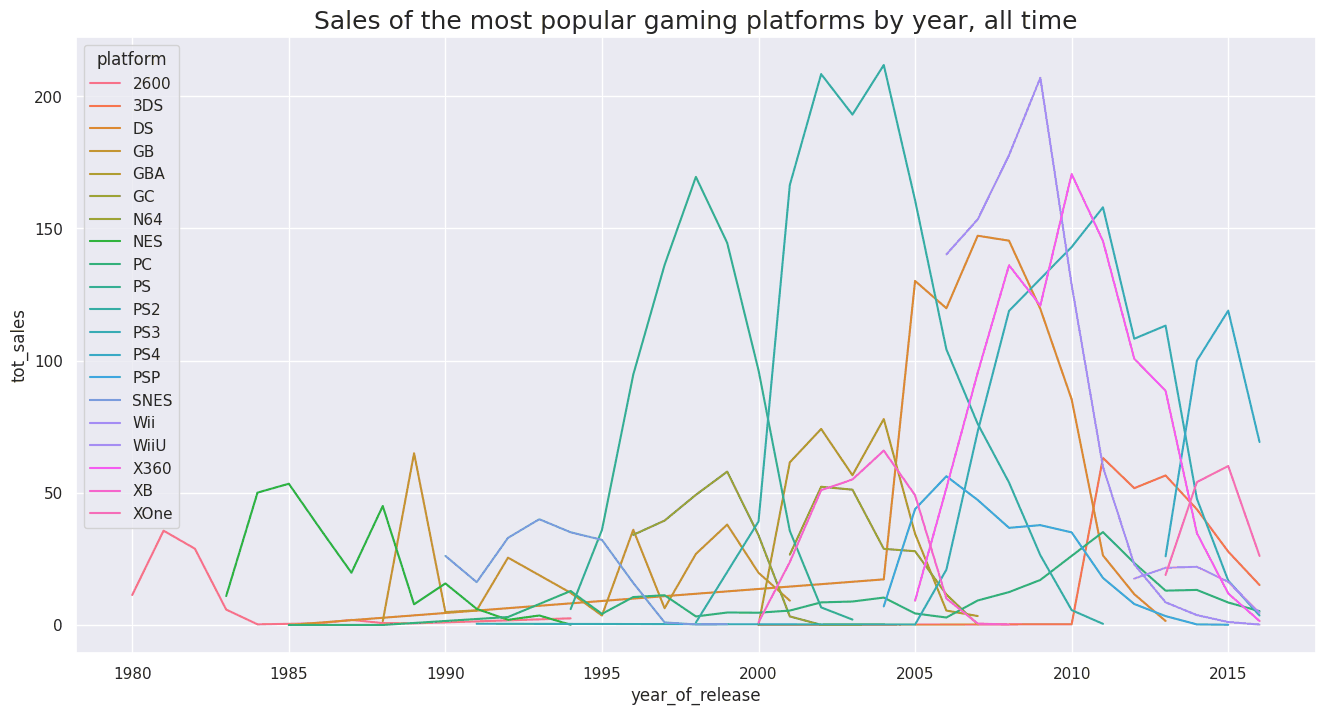

In [55]:
def show_lines(data, year, title):
    """
    input: data [pd.DataFrame] - table of data to plot
           year [int16] - first year to plot
           title [str] - plot title
    output: None
    description: The function plots total sales by year for the selected platforms
                 seaborn's lineplot() is used
    """
    plt.figure(figsize=(16,8))
    plt.title(title, fontsize=18)
    sns.lineplot(x='year_of_release',
                y='tot_sales',
                hue='platform',
                markers=True,
                data=(data
                      .query('year_of_release >= @year')              # almost all current platforms appeared after 2000
                      .groupby(['platform','year_of_release'])['tot_sales']   # group by platform and year
                      .agg('sum')                                             # total sales by platform and year
                      .reset_index()
                     )
                )
show_lines(games.query('platform in @top_platforms'), 
           1980, 
           'Sales of the most popular gaming platforms by year, all time')

- The plot shows that the main platforms were popular for **5 to 10 years**.

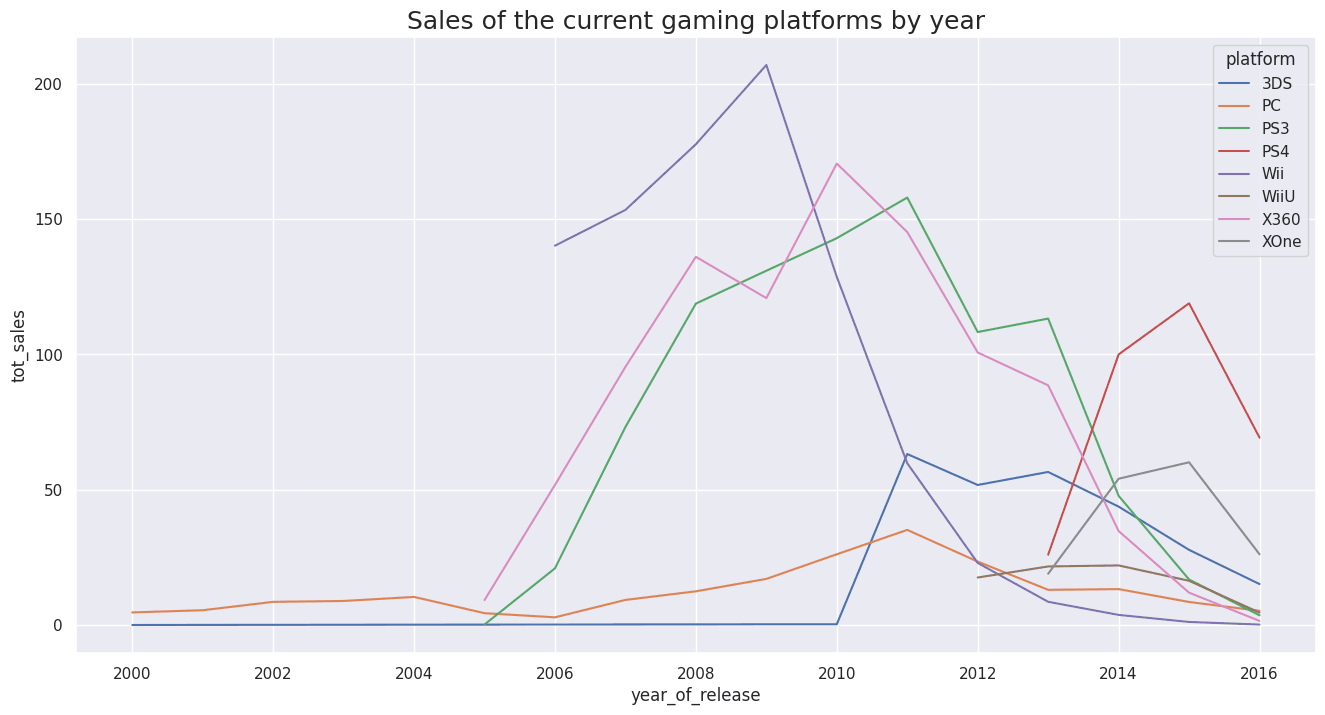

In [56]:
# slice of the original table: current platforms that are also among the platforms with the highest sales
games_actual = games.query('platform in @top_platforms and platform in @cur_platforms')
# plot total sales by year for the platforms that are current in 2016
show_lines(games_actual, 
           2000, 
           'Sales of the current gaming platforms by year')

- The plot shows that most platforms that are current in 2016 appeared after 2010.
The **current period is therefore 2010-2016**.
- Note also that 'PS3' and 'X360', which were current in 2010, had almost completely lost their sales by 2016, because they were replaced in 2013 by the new generations of platforms ('PS4', 'Wii' and 'XOne'). It makes no sense to promote old platforms, so they are not considered in the analysis.
- The platforms for the study: **'PS4', '3DS', 'XOne', 'WiiU', 'PC'**.
- Plot the total sales by year for the current platforms over the current period.

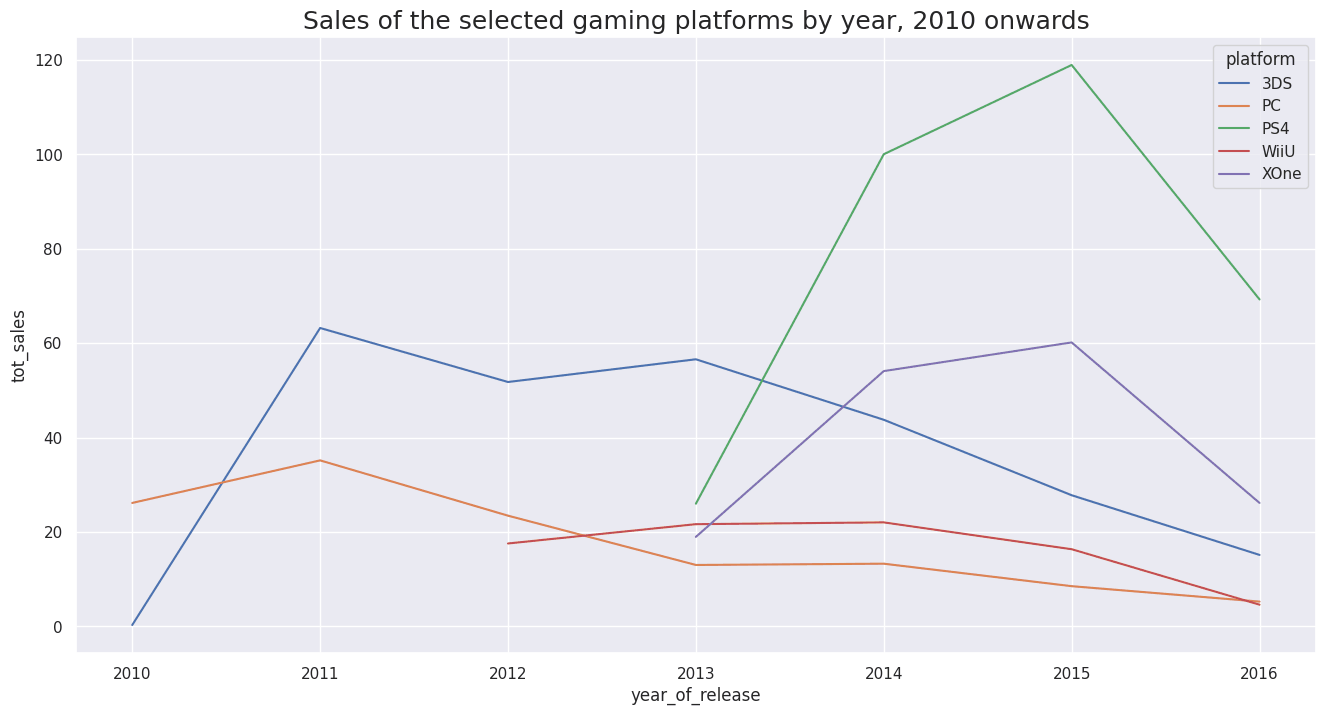

In [57]:
act_platforms = ['PS4', '3DS', 'XOne', 'WiiU', 'PC']
show_lines(games.query('platform in @act_platforms'), 
           2010, 
           'Sales of the selected gaming platforms by year, 2010 onwards')

In [58]:
# take a slice of the data: current platforms and release period
games_actual = games_actual.query('platform in @act_platforms and year_of_release >= 2010')

- The drop in sales of 'PS4', 'WiiU' and 'XOne' in 2016 is most likely explained by incomplete data (the year was not over when the data was collected).
- Changes in total sales of the selected platforms over time:
    - 'PS4' and 'XOne' show growing total sales from 2013 to 2015.
    - 'PS4' is the sales leader at the end of 2015 and at the moment of data collection in 2016.
    - Total sales of '3DS' have been slowly declining since 2011.
    - Total sales of 'WiiU' are almost constant, staying at about 20 million copies from 2012 to 2015.
    - Total sales of 'PC' games are low (a maximum of 35 million copies in 2011) and have been slowly declining since 2011.
    However, 'PC' games have been sold since the 1980s, with smooth rises and falls. In this sense 'PC' is the most stable of the platforms considered.

### 3.2 Sales by Current Platform

Build a box plot of global game sales by platform.

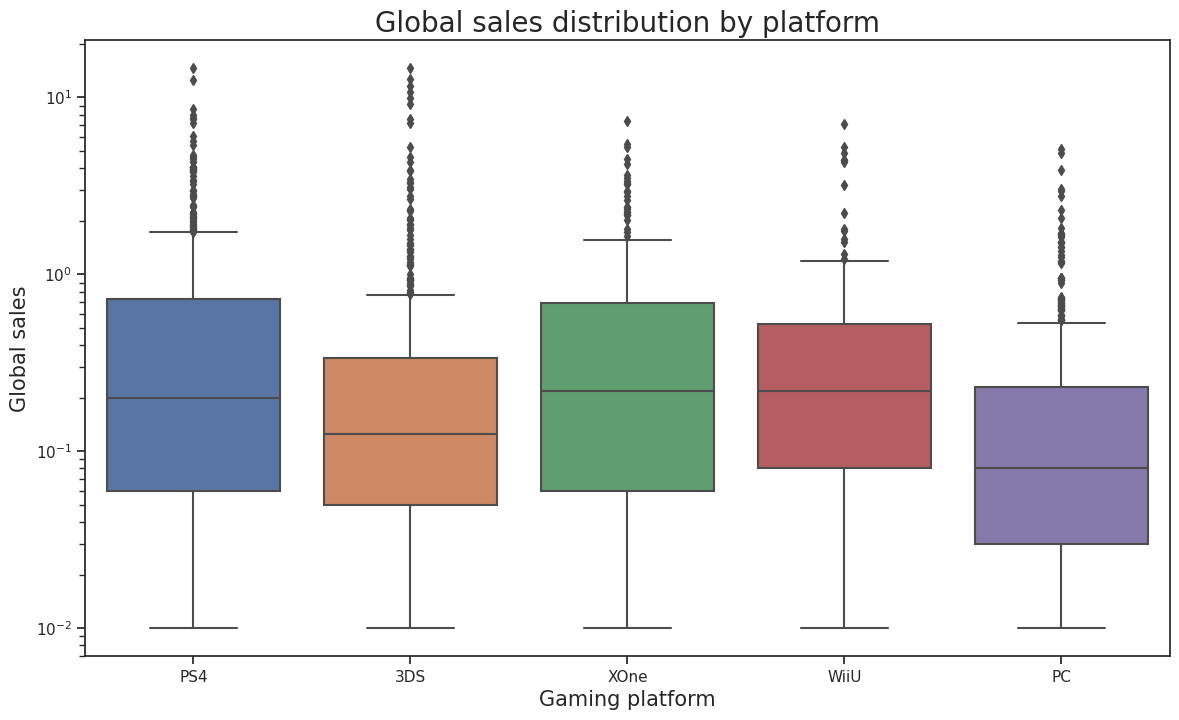

In [59]:
# plot the distribution of global sales with boxplot() from seaborn.
# use a logarithmic axis for clarity (many outliers distort the boxplot)
plt.figure(figsize=(14,8))
sns.set(style="ticks")
ax = sns.boxplot(data=games_actual, y="tot_sales", x='platform')
ax.set_title('Global sales distribution by platform', fontsize=20)
ax.set_xlabel('Gaming platform', fontsize=15)
ax.set_ylabel('Global sales', fontsize=15)
ax.set(yscale="log")
plt.show()

Find the overall share of outliers in global sales across all platforms.

In [60]:
games_actual['tot_sales'].describe()

count    1788.000000
mean        0.525157
std         1.231056
min         0.010000
25%         0.040000
50%         0.130000
75%         0.430000
max        14.630000
Name: tot_sales, dtype: float64

In [61]:
print('Share of outliers in the data:',
      round(len(games_actual.loc[games_actual['tot_sales'] >= (0.43-0.04)*1.5+0.43]) / len(games_actual) * 100, 2), '%')

Share of outliers in the data: 12.3 %


- The data still has many outliers (12.3% of the data). This is a property of the dataset, so they are left as is.
Global sales on all platforms are strongly right-skewed. There is a fairly large number of games with very high sales compared with the average values.
- The median global sales of 'PS4', 'XOne' and 'WiiU' are about the same (0.2 million copies). 'WiiU' has a slightly smaller variance than 'PS4' and 'XOne'. However, the total sales by year of 'PS4' and 'XOne' are noticeably higher than those of 'WiiU'. The large number of outliers (games with very high sales) on 'PS4' and 'XOne' increases their total sales considerably.
- 'PC' has the lowest median global sales.

### 3.3 Influence of User and Critic Reviews on Sales on the 'PC' Platform

- Look at how user and critic reviews influence sales within `PC`.
    - Build a scatter plot with `pairplot` from `seaborn`
    - Calculate the correlation between the reviews and the sales.

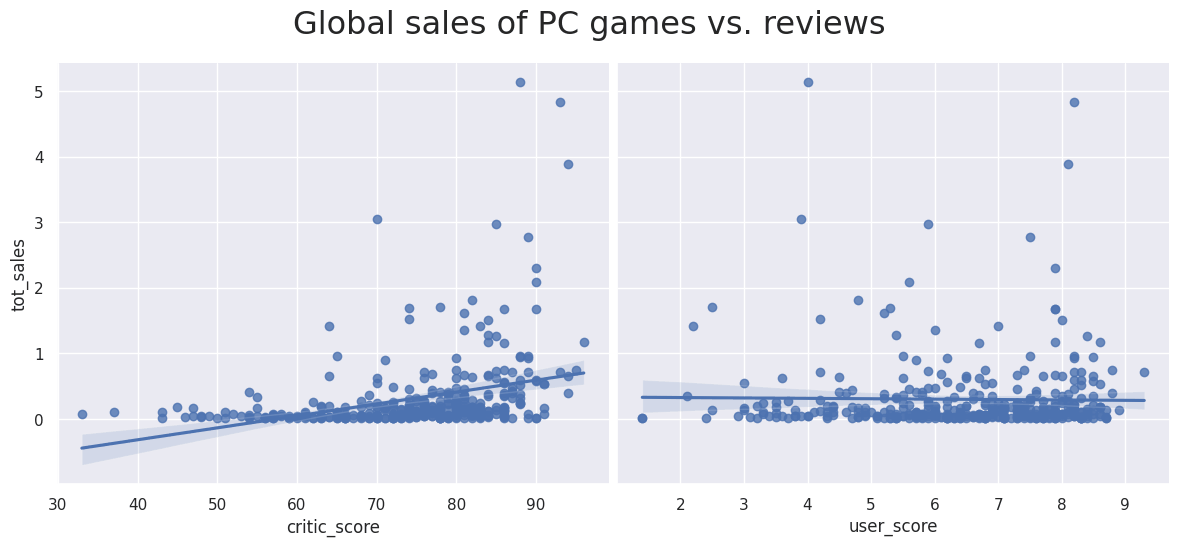

In [62]:
# take a slice of the data for the PC platform and save it in games_pc.
games_pc = games_actual.loc[(games_actual['platform'] == 'PC')]
sns.set()
ax = sns.pairplot(games_pc,                                # pairplot shows the plots together
                  x_vars=['critic_score','user_score'],    # dependence of sales on critic_score and user_score
                  y_vars=['tot_sales'],
                  height=5, aspect=1.2, 
                  kind="reg"                               # show the regression line
            )
ax.fig.suptitle("Global sales of PC games vs. reviews", y=1.08, size=23)
plt.show()

In [63]:
# calculate the correlation coefficients between global sales of PC games and game reviews
games_pc[['tot_sales', 'critic_score','user_score']].corr()

,tot_sales,critic_score,user_score
tot_sales,1.000000,0.337270,-0.016365
critic_score,0.337270,1.000000,0.478382
user_score,-0.016365,0.478382,1.000000


<Axes: >

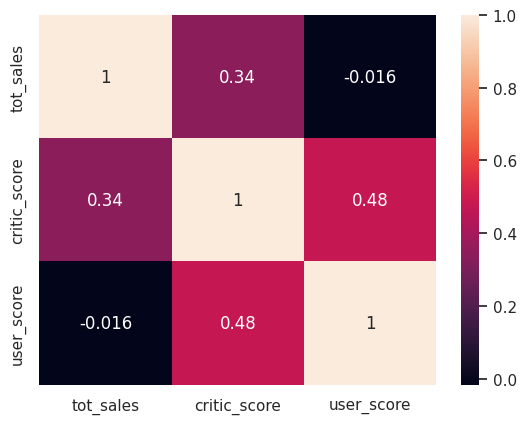

In [64]:
# visualize the correlation matrix with seaborn's heatmap
sns.heatmap(games_pc[['tot_sales', 'critic_score', 'user_score']].corr(), annot=True)

- The plots show a weak correlation between global sales of PC games and critic scores. This is confirmed by the correlation coefficient **0.34**.
- There is no correlation between global sales of PC games and user scores. This is confirmed by the correlation coefficient **-0.02**. The negative value may be caused by outliers.
- Look at the correlation coefficients without the influence of outliers.
According to the box plot in the previous section, outliers for the PC platform start at global sales of **0.6**. Take a slice of the data below this value and calculate the correlation coefficients.

In [65]:
(games_pc
 .loc[games_pc['tot_sales'] <= 0.6]
 [['tot_sales', 'critic_score','user_score']]
 .corr()
)

,tot_sales,critic_score,user_score
tot_sales,1.000000,0.381768,0.036176
critic_score,0.381768,1.000000,0.495483
user_score,0.036176,0.495483,1.000000


- The correlation coefficients are almost unchanged.
    - corr('tot_sales', 'critic_score') = 0.38
    - corr('tot_sales', 'user_score') = 0.04 (now the value is positive).

- Find the correlation coefficients for the other platforms and compare the results.

In [66]:
(games_actual
 .groupby(['platform'])
 [['tot_sales','critic_score','user_score']]
 .agg('corr')
 .reset_index()
 .query('level_1 == "tot_sales"')
 .iloc[:,[0,1,3,4]]
)

,platform,level_1,critic_score,user_score
0,3DS,tot_sales,0.348216,0.222305
3,PC,tot_sales,0.337270,-0.016365
6,PS4,tot_sales,0.406568,-0.031957
9,WiiU,tot_sales,0.348380,0.400219
12,XOne,tot_sales,0.416998,-0.068925


- There is a weak correlation between global sales and critic scores **(0.34 - 0.42)** on all gaming platforms.
- There is no correlation between global sales and user scores on `PS4`, `XOne` and `PC`.
However, `3DS` shows a weak correlation of **0.22** between these parameters.
On `WiiU` the correlation is even higher **(0.4)** (higher than the correlation with critic scores).
- It can be concluded that users of the `WiiU` platform are interested in the opinions of other players (besides critic scores) before buying a new game.
- In general, critic scores matter more for promoting a gaming platform (although players should not be forgotten either, since games are made for them).

### 3.4 Influence of the Game Genre on Sales

- Look at the overall distribution of games by genre.

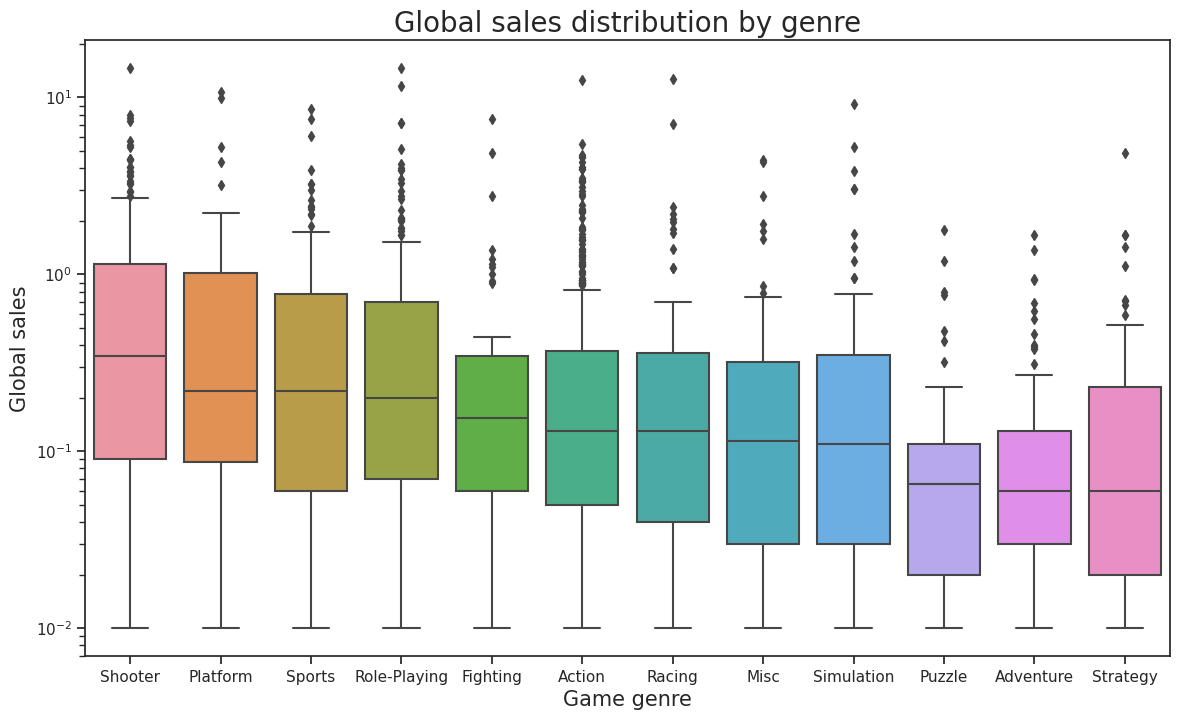

In [67]:
# sort the genres by descending median global sales
genres_sorted = (games_actual
                 .groupby('genre')['tot_sales']
                 .agg('median')
                 .sort_values(ascending=False)
                 .index
                )
# plot the distribution of global sales with boxplot() from seaborn.
# plot on a logarithmic axis for clarity (many outliers distort the boxplot)
plt.figure(figsize=(14,8))
sns.set(style="ticks")
ax = sns.boxplot(data=games_actual, y="tot_sales", x='genre', order = genres_sorted)
# order = genres_sorted - arrange the boxes by descending global sales
ax.set_title('Global sales distribution by genre', fontsize=20)
ax.set_xlabel('Game genre', fontsize=15)
ax.set_ylabel('Global sales', fontsize=15)
ax.set(yscale="log")
plt.show()

- The most popular and best-selling genre is `Shooter` (median **0.35 million copies** across all platforms).
`Platform`, `Sports` and `Role-Playing` are also popular (median **0.2 million copies** across all platforms).
These are the genres to pay attention to when promoting gaming platforms.
- The least selling genres are `Puzzle`, `Adventure` and `Strategy` (median **0.06 million copies** across all platforms).
- All genres have many outliers. Every genre has popular games with sales orders of magnitude above the average.

### Conclusions

- The global sales levels of the gaming platforms are analyzed. The main popular platforms in 2016 are **'PS4', '3DS', 'XOne', 'WiiU', 'PC'**.
- The current period for the study is **2010-2016**.
The changes in sales of the selected platforms over this period are examined.
- `PS4` is the leader in total sales. However, the median values for `XOne` and `WiiU` are higher than for `PS4`. This difference is caused by the large number of outliers (popular games with high sales). The share of outliers is about **12%**.
- `PC` has the lowest median global sales. However, 'PC' games have been sold since the 1980s, with smooth rises and falls. In this sense 'PC' is the most stable of the platforms considered.
- The influence of user and critic reviews on sales is studied for the 'PC' platform, and the correlation coefficients between sales and scores are calculated for all platforms.
    - There is a weak correlation between global sales and critic scores **(0.34 - 0.42)** on all gaming platforms.
    - There is no correlation between global sales and user scores on `PS4`, `XOne` and `PC`.
    `3DS` shows a weak correlation of **0.22** between these parameters.
    On `WiiU` the correlation is even higher **(0.4)**. Users of `WiiU` are interested in the opinions of other players (besides critic scores) before buying a new game.
    - In general, critic scores matter more for promoting a gaming platform.
- The influence of the game genre on sales is studied.
    - The most popular and best-selling genre is Shooter (median **0.35 million copies** across all platforms).
    - The least selling genres are `Puzzle`, `Adventure` and `Strategy` (median **0.06 million copies**).
    - All genres have many outliers. Every genre has popular games with sales orders of magnitude above the average.

## Step 4. User Profile of Each Region

- Determine for the users of each region (NA, EU, JP):
    - The most popular platforms (top 5) and the differences in their sales shares.
    - The most popular genres (top 5).
    - The influence of the ESRB rating on sales in each region.

**1)** Build a pivot table of sales shares by platform for each region:

In [68]:
platform_fracs = (games
                  .loc[games['year_of_release'] >= 2010]                     # slice for the current period;
                  .groupby('platform')[['na_sales', 'eu_sales', 'jp_sales']] # group by platform;
                  .agg('sum')                                                # sum of regional sales for each platform;
                  .apply(lambda x: round(x / float(x.sum()), 2))             # share of each platform
                 )                                                           # in the total regional sales for the current period;
platform_fracs

,na_sales,eu_sales,jp_sales
platform,,,
3DS,0.07,0.07,0.33
DS,0.05,0.03,0.09
PC,0.04,0.08,0.00
PS2,0.00,0.00,0.00
PS3,0.20,0.25,0.19
PS4,0.10,0.17,0.05
PSP,0.01,0.01,0.14
PSV,0.01,0.02,0.07
Wii,0.11,0.08,0.06


In [69]:
print('Top 5 platforms for North America:')
display(platform_fracs
        .sort_values(by='na_sales',ascending=False)   # sort in descending order and take the top 5
        .head(5)
       )

Top 5 platforms for North America:


,na_sales,eu_sales,jp_sales
platform,,,
X360,0.30,0.19,0.02
PS3,0.20,0.25,0.19
Wii,0.11,0.08,0.06
PS4,0.10,0.17,0.05
XOne,0.08,0.06,0.00


In [70]:
print('Top 5 platforms for Europe:')
display(platform_fracs
        .sort_values(by='eu_sales',ascending=False)
        .head(5)
       )

Top 5 platforms for Europe:


,na_sales,eu_sales,jp_sales
platform,,,
PS3,0.20,0.25,0.19
X360,0.30,0.19,0.02
PS4,0.10,0.17,0.05
PC,0.04,0.08,0.00
Wii,0.11,0.08,0.06


In [71]:
print('Top 5 platforms for Japan:')
display(platform_fracs
        .sort_values(by='jp_sales',ascending=False)
        .head(5)
       )

Top 5 platforms for Japan:


,na_sales,eu_sales,jp_sales
platform,,,
3DS,0.07,0.07,0.33
PS3,0.20,0.25,0.19
PSP,0.01,0.01,0.14
DS,0.05,0.03,0.09
PSV,0.01,0.02,0.07


- Europe and North America have similar platform preferences. The top 5 contains different generations of `PS`, `Nintendo` (Wii) and `Xbox`. Europe also prefers games on `PC`.
- In Japan, besides `PS`, the `DS` family of platforms is popular.
- This may be caused by the differences between the Japanese and the global video game markets. Many games are created in Japan for local platforms and the local audience (without entering the international market).

**2)** Build a pivot table of sales shares by genre for each region:

In [72]:
genres_fracs = (games
                  .loc[games['year_of_release'] >= 2010]                     # slice for the current period;
                  .groupby('genre')[['na_sales', 'eu_sales', 'jp_sales']]    # group by genre;
                  .agg('sum')                                                # sum of regional sales for each genre;
                  .apply(lambda x: round(x / float(x.sum()), 2))             # share of each genre
                 )                                                           # in the total regional sales for the current period;
genres_fracs

,na_sales,eu_sales,jp_sales
genre,,,
Action,0.26,0.28,0.24
Adventure,0.02,0.02,0.05
Fighting,0.03,0.02,0.05
Misc,0.11,0.08,0.08
Platform,0.05,0.05,0.05
Puzzle,0.01,0.01,0.01
Racing,0.04,0.06,0.02
Role-Playing,0.10,0.09,0.34
Shooter,0.21,0.20,0.05


In [73]:
print('Top 5 genres for North America:')
display(genres_fracs
        .sort_values(by='na_sales',ascending=False)   # sort in descending order and take the top 5
        .head(5)
       )

Top 5 genres for North America:


,na_sales,eu_sales,jp_sales
genre,,,
Action,0.26,0.28,0.24
Shooter,0.21,0.20,0.05
Sports,0.14,0.14,0.05
Misc,0.11,0.08,0.08
Role-Playing,0.10,0.09,0.34


In [74]:
print('Top 5 genres for Europe:')
display(genres_fracs
        .sort_values(by='eu_sales',ascending=False)   # sort in descending order and take the top 5
        .head(5)
       )

Top 5 genres for Europe:


,na_sales,eu_sales,jp_sales
genre,,,
Action,0.26,0.28,0.24
Shooter,0.21,0.20,0.05
Sports,0.14,0.14,0.05
Role-Playing,0.10,0.09,0.34
Misc,0.11,0.08,0.08


In [75]:
print('Top 5 genres for Japan:')
display(genres_fracs
        .sort_values(by='jp_sales',ascending=False)   # sort in descending order and take the top 5
        .head(5)
       )

Top 5 genres for Japan:


,na_sales,eu_sales,jp_sales
genre,,,
Role-Playing,0.10,0.09,0.34
Action,0.26,0.28,0.24
Misc,0.11,0.08,0.08
Adventure,0.02,0.02,0.05
Fighting,0.03,0.02,0.05


- The top 5 genres of Europe and North America are almost the same: `Action`, `Shooter`, `Sports`, `Misc`, `Role-Playing`. This also shows that these regions are parts of the global game market: they play the same games.
- The Japanese market is different. Besides `Role-Playing`, `Action` and `Misc`, players there like `Fighting` and `Adventure`, and buy far fewer `Shooter` and `Sports` games than in the other regions. This may be caused by the players' mentality and by the isolation of the market.

**3)** Build a pivot table of sales shares by ESRB rating for each region:

In [76]:
rating_fracs = (games
                  .loc[games['year_of_release'] >= 2010]                     # slice for the current period;
                  .groupby('rating')[['na_sales', 'eu_sales', 'jp_sales']]    # group by ESRB rating;
                  .agg('sum')                                                # sum of regional sales for each rating;
                  .apply(lambda x: round(x / float(x.sum()), 2))             # share of each rating
                 )                                                           # in the total regional sales for the current period;
rating_fracs

,na_sales,eu_sales,jp_sales
rating,,,
E,0.28,0.28,0.36
E10+,0.16,0.14,0.10
M,0.39,0.42,0.23
T,0.16,0.16,0.32


- By ESRB rating, North America and Europe are also very similar. Most games are bought with the ratings 'M' (17+) and 'E' (everyone), and less often 'E10+' and 'T'. This may be caused by the players' demand for adult content ('M') and by the companies' wish to reach as many age groups as possible (category 'E').
- The Japanese market is different. Most games are bought for children and teenagers (categories 'E' and 'T'). Adult games are bought less than in Europe and North America on average. This is also explained by the players' mentality.

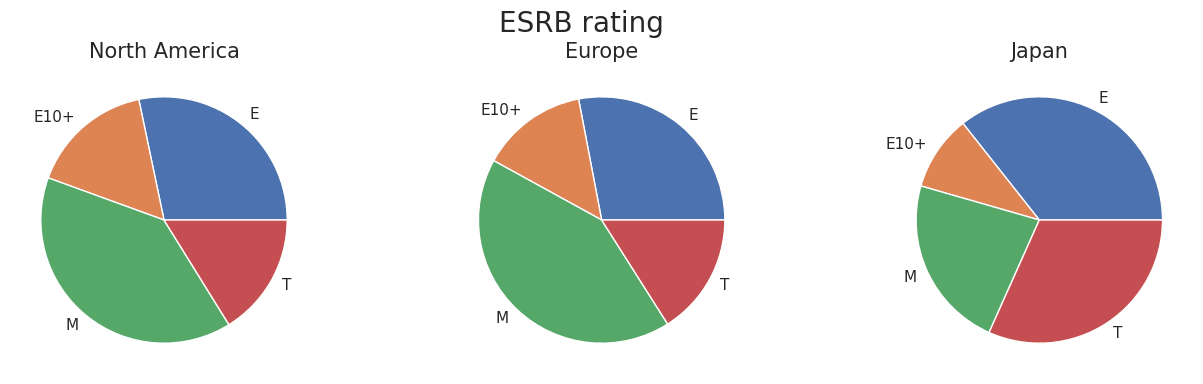

In [77]:
# Visualize the user profiles by ESRB rating with pie charts.
fig = plt.figure(figsize=(16,4))
fig.suptitle('ESRB rating', fontsize=20, y=1.02)
ax1 = plt.subplot(131)
plt.pie(rating_fracs['na_sales'], labels=rating_fracs.index)
ax1.set_title('North America', fontsize=15)

ax2 = plt.subplot(132)
plt.pie(rating_fracs['eu_sales'], labels=rating_fracs.index)
ax2.set_title('Europe', fontsize=15)

ax3 = plt.subplot(133)
plt.pie(rating_fracs['jp_sales'], labels=rating_fracs.index)
ax3.set_title('Japan', fontsize=15)
plt.show()

### Conclusions

- The top 5 platforms with the highest sales shares are found for North America, Europe and Japan.
    - Europe and North America have similar platform preferences. The top 5 contains different generations of `PS`, `Nintendo` (Wii) and `Xbox`. Europe also prefers games on `PC`.
    - In Japan, besides `PS`, the `DS` family of platforms is popular.
- The top 5 genres with the highest sales shares are found for North America, Europe and Japan.
    - For Europe and North America the genres are almost the same: `Action`, `Shooter`, `Sports`, `Misc`, `Role-Playing`.
    - In Japan, besides `Role-Playing`, `Action` and `Misc`, players like `Fighting` and `Adventure`, and buy far fewer `Shooter` and `Sports` games.
- The dependence of game sales on the ESRB rating is analyzed for each region.
    - In Europe and North America most games are bought with the ratings 'M' (17+) and 'E' (everyone). This may be caused by the players' demand for adult content ('M') and by the companies' wish to reach as many age groups as possible (category 'E').
    - In Japan most games are bought for children and teenagers (categories 'E' and 'T').
- The differences between the sales in Japan and in the other regions are explained by the players' mentality and by the isolation of the Japanese market. Many games are created in Japan for the domestic market and for local platforms.

## Step 5. Hypothesis Testing

### 5.1 Removing Outliers in User Scores

- First, look at the outliers in `user_score` and remove them where possible.

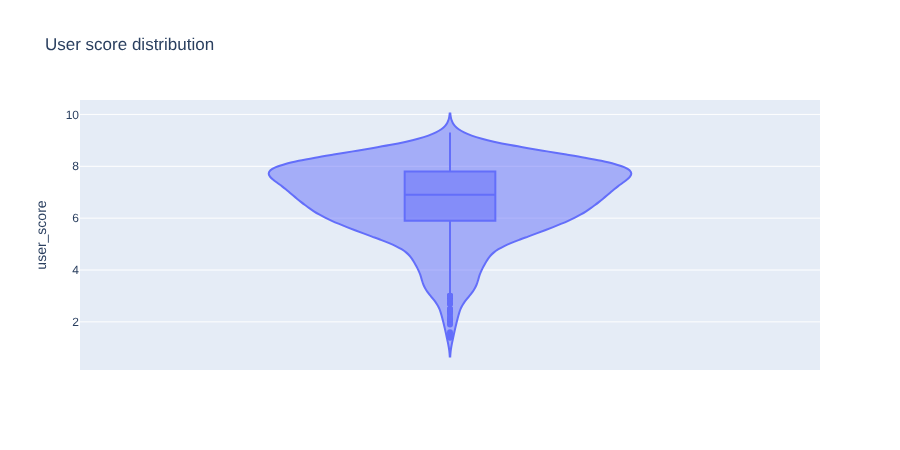

In [78]:
# plot the distribution of user scores with violin() from plotly
# box=True - to show a box plot inside the violin
px.violin(games_actual, y="user_score", 
          box=True, title = 'User score distribution')

In [79]:
print('Share of outliers in the data:',
      round(len(games_actual.loc[games_actual['user_score'] <= 3]) / games_actual['user_score'].count() * 100, 2), '%')

Share of outliers in the data: 2.47 %


- The share of outliers is low (2.5% of all user scores). Remove them without harming the data distributions.

In [80]:
games_actual = games_actual.loc[(games_actual['user_score'].isna()) |
                               (games_actual['user_score'] > 3)]

### 5.2 Average User Ratings of the Xbox One and PC Platforms

- Hypothesis to test:
    - "The average user ratings of the Xbox One and PC platforms are the same"
- Null hypothesis H0:
    - "The average user score of games on Xbox One is equal to the average user score of games on PC"
- Alternative hypothesis H1:
    - "The average user score of games on Xbox One is not equal to the average user score of games on PC"
- Significance level: `alpha = 0.05`
- The score samples for `XOne` and `PC` are independent. Use Student's t-test `st.ttest_ind` to calculate the test statistic and the `p-value`.

In [81]:
# save in games_xone and games_pc the slices of user scores for the platforms 'XOne' and 'PC' respectively
games_xone = games_actual.loc[(games_actual['platform'] == 'XOne') &
                              (~games_actual['user_score'].isna()), 
                              'user_score']
games_pc = games_actual.loc[(games_actual['platform'] == 'PC') &
                              (~games_actual['user_score'].isna()), 
                              'user_score']

- Student's t-test requires the samples to be normally distributed and their variances not to differ strongly.
- Check the normality of `games_xone` and `games_pc` with a Q-Q plot.

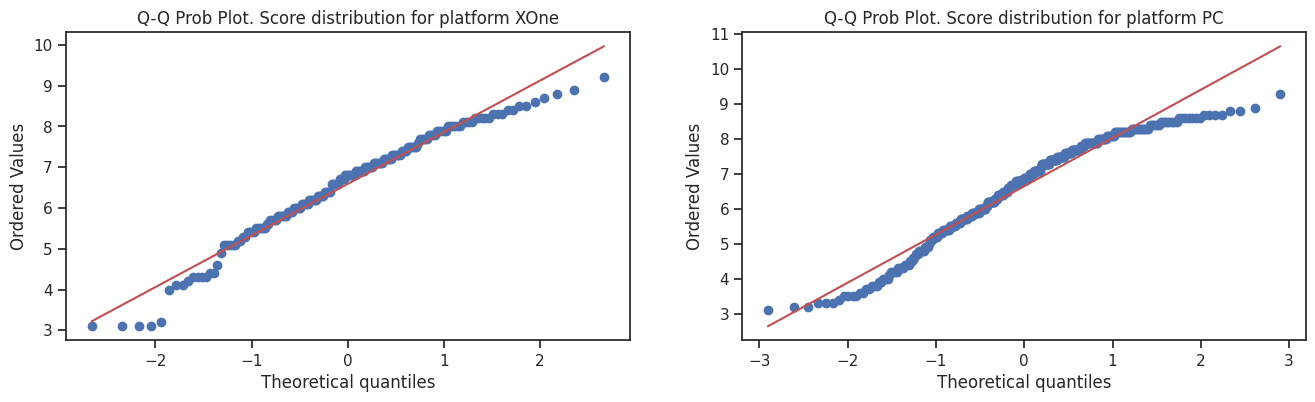

In [82]:
plt.figure(figsize=(16,4))
ax1 = plt.subplot(121)
# plot quantile-quantile plots with probplot() from the stats library for both samples
st.probplot(games_xone, dist="norm", plot=plt)
ax1.set_title('Q-Q Prob Plot. Score distribution for platform XOne')
ax2 = plt.subplot(122)
st.probplot(games_pc, dist="norm", plot=plt)
ax2.set_title('Q-Q Prob Plot. Score distribution for platform PC')
plt.show()

- The plots show that the sample distributions are close to normal.
- Additionally, check the equality of the sample variances with Levene's test.
- Null and alternative hypotheses of Levene's test:
**H0**: All k sample populations have equal variances.
**H1**: At least one of the k sample population variances is not equal to the others.
Significance level **alpha** = **0.05**

In [83]:
# use levene() from the stats library
stat, p = st.levene(games_xone, games_pc)
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))

Statistics = 3.921, p-value = 0.048


- The p-value is less than alpha, so there is evidence that the variances of `games_xone` and `games_pc` differ slightly. Student's t-test is still applicable; it is run with `equal_var=False` (Welch's variant) to account for this.

In [84]:
# use ttest_ind() from the stats library
stat, p = st.ttest_ind(games_xone, games_pc, equal_var=False)   # assume the sample variances are different
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))

Statistics = -0.485, p-value = 0.628


- The `p-value` is **0.63** > `alpha`, so there is no reason to reject the null hypothesis. The data does not contradict H0:
- "The average user score of games on Xbox One is equal to the average user score of games on PC"

### 5.3 Average User Ratings of the Action and Sports Genres

- Hypothesis to test:
    - "The average user ratings of the Action and Sports genres are different"
- Null hypothesis H0:
    - "The average user score of Action games is equal to the average user score of Sports games"
- Alternative hypothesis H1:
    - "The average user score of Action games is not equal to the average user score of Sports games"
- Significance level: `alpha = 0.05`
- The score samples for `Action` and `Sports` are independent. Use Student's t-test `st.ttest_ind` to calculate the test statistic and the `p-value`.

In [85]:
# save in games_action and games_sports the slices
# of user scores for the genres 'Action' and 'Sports' respectively
games_action = games_actual.loc[(games_actual['genre'] == 'Action') &
                              (~games_actual['user_score'].isna()), 
                              'user_score']
games_sports = games_actual.loc[(games_actual['genre'] == 'Sports') &
                              (~games_actual['user_score'].isna()), 
                              'user_score']

- Student's t-test requires the samples to be normally distributed and their variances not to differ strongly.
- Check the normality of `games_action` and `games_sports` with a Q-Q plot.

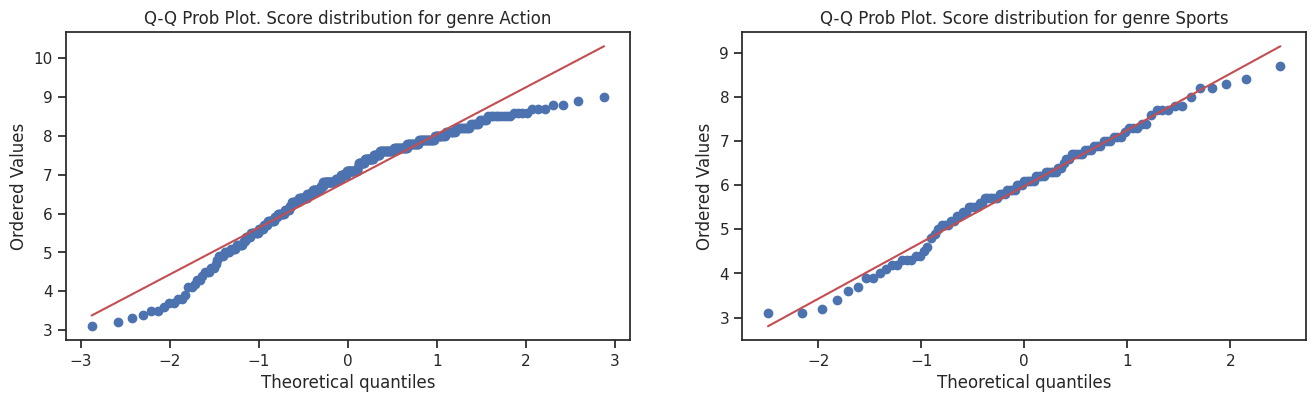

In [86]:
plt.figure(figsize=(16,4))
ax1 = plt.subplot(121)
# plot quantile-quantile plots with probplot() from the stats library for both samples
st.probplot(games_action, dist="norm", plot=plt)
ax1.set_title('Q-Q Prob Plot. Score distribution for genre Action')
ax2 = plt.subplot(122)
st.probplot(games_sports, dist="norm", plot=plt)
ax2.set_title('Q-Q Prob Plot. Score distribution for genre Sports')
plt.show()

- The plots show that the sample distributions are close to normal.
- Additionally, check the equality of the sample variances with Levene's test.
- Null and alternative hypotheses of Levene's test:
**H0**: All k sample populations have equal variances.
**H1**: At least one of the k sample population variances is not equal to the others.
Significance level **alpha** = **0.05**

In [87]:
# use levene() from the stats library
stat, p = st.levene(games_action, games_sports)
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))

Statistics = 0.105, p-value = 0.746


- The p-value is greater than alpha, so there is no reason to believe that the variances of `games_action` and `games_sports` differ.
- Student's t-test can be used to test the original hypothesis.

In [88]:
# use ttest_ind() from the stats library
stat, p = st.ttest_ind(games_action, games_sports, equal_var=True)   # assume the sample variances are equal
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))

Statistics = 6.296, p-value = 0.000


- The `p-value` is almost 0 (much less than `alpha`), so the null hypothesis H0 is very unlikely. The data allows rejecting the null hypothesis in favor of the alternative H1:
- "The average user score of Action games is not equal to the average user score of Sports games"

### Conclusions

- First hypothesis:
The data does not contradict H0:
    - "The average user score of games on Xbox One is equal to the average user score of games on PC"
    The original hypothesis is confirmed.
- Second hypothesis:
The data allows rejecting the null hypothesis in favor of the alternative H1:
    - "The average user score of Action games is not equal to the average user score of Sports games"
    The original hypothesis is confirmed.

## Step 6. Overall Conclusion

**1)** The data is loaded successfully. The table `games` has 16715 records. No duplicates are found. The data matches the description.

**2)** The data types are converted to match the stored information.
- The missing values are studied and handled.
    - The share of missing values reaches 55%.
    - Possible reasons for the missing values: the information was absent when the data was collected, or a failure occurred during the export from the database.
- The distributions of the numerical parameters are studied.
    - The sales data is strongly right-skewed. The share of outliers reaches 11.3%.
    Most games sell up to 1.09 million copies worldwide, but a number of very popular games sell up to 82.5 million copies. These games skew the data.
    - The score data is slightly left-skewed. The share of outliers reaches 4%.

**3)**
- The global sales levels of the gaming platforms are analyzed. The main popular platforms in 2016 are **'PS4', '3DS', 'XOne', 'WiiU', 'PC'**.
- The current period for the study is **2010-2016**.
- `PS4` is the leader in total sales. However, the median values for `XOne` and `WiiU` are higher than for `PS4`. This difference is caused by the large number of outliers (popular games with high sales). The share of outliers is about **12%**.
- There is a weak correlation between global sales and critic scores **(0.34 - 0.42)** on all gaming platforms. `3DS` shows a weak correlation of **0.22** between sales and user scores. On `WiiU` the correlation is even higher **(0.4)**. Users of `WiiU` are interested in the opinions of other players (besides critic scores) before buying a new game.
- The influence of the game genre on sales is studied.
    - The most popular and best-selling genre is Shooter (median **0.35 million copies** across all platforms).
    - The least selling genres are `Puzzle`, `Adventure` and `Strategy` (median **0.06 million copies**).
    - All genres have many outliers. Every genre has popular games with sales orders of magnitude above the average.

**4)**
- The top 5 platforms with the highest sales shares are found for North America, Europe and Japan.
    - Europe and North America have similar platform preferences. The top 5 contains different generations of `PS`, `Nintendo` (Wii) and `Xbox`. Europe also prefers games on `PC`.
    - In Japan, besides `PS`, the `DS` family of platforms is popular.
- The top 5 genres with the highest sales shares are found for North America, Europe and Japan.
    - For Europe and North America the genres are almost the same: `Action`, `Shooter`, `Sports`, `Misc`, `Role-Playing`.
    - In Japan, besides `Role-Playing`, `Action` and `Misc`, players like `Fighting` and `Adventure`, and buy far fewer `Shooter` and `Sports` games.
- The dependence of game sales on the ESRB rating is analyzed for each region.
    - In Europe and North America most games are bought with the ratings 'M' (17+) and 'E' (everyone). This may be caused by the players' demand for adult content ('M') and by the companies' wish to reach as many age groups as possible (category 'E').
    - In Japan most games are bought for children and teenagers (categories 'E' and 'T').
- The differences between the sales in Japan and in the other regions are explained by the players' mentality and by the isolation of the Japanese market. Many games are created in Japan for the domestic market and for local platforms.

**5)**
- First hypothesis:
The data does not contradict H0:
    - "The average user score of games on Xbox One is equal to the average user score of games on PC"
    The original hypothesis is confirmed.
- Second hypothesis:
The data allows rejecting the null hypothesis in favor of the alternative H1:
    - "The average user score of Action games is not equal to the average user score of Sports games"
    The original hypothesis is confirmed.